In [4]:
import pandas as pd

df = pd.read_csv("water_potability.csv")
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [44]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

Dataset shape: (3276, 10)

Columns:
Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')


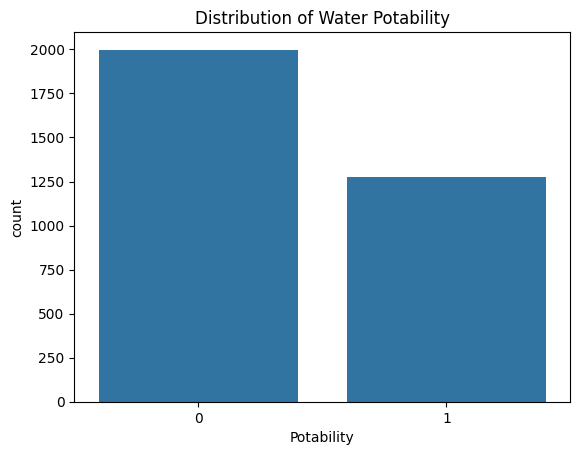

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Potability', data=df)
plt.title("Distribution of Water Potability")
plt.show()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [46]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


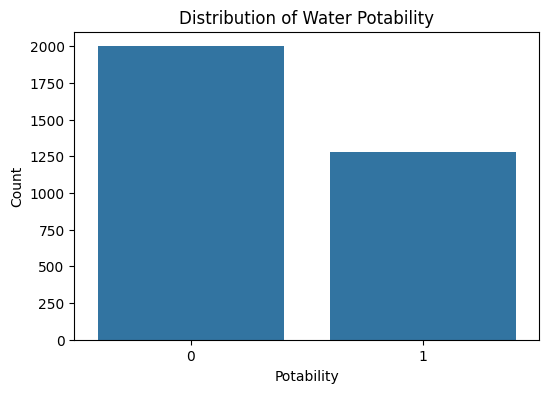

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Potability")

plt.title("Distribution of Water Potability")
plt.xlabel("Potability")
plt.ylabel("Count")

plt.show()

In [48]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

missing.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
Sulfate,781,23.840049
ph,491,14.987790
Trihalomethanes,162,4.945055
Hardness,0,0.000000
Chloramines,0,0.000000
Solids,0,0.000000
Conductivity,0,0.000000
Organic_carbon,0,0.000000
Turbidity,0,0.000000
Potability,0,0.000000


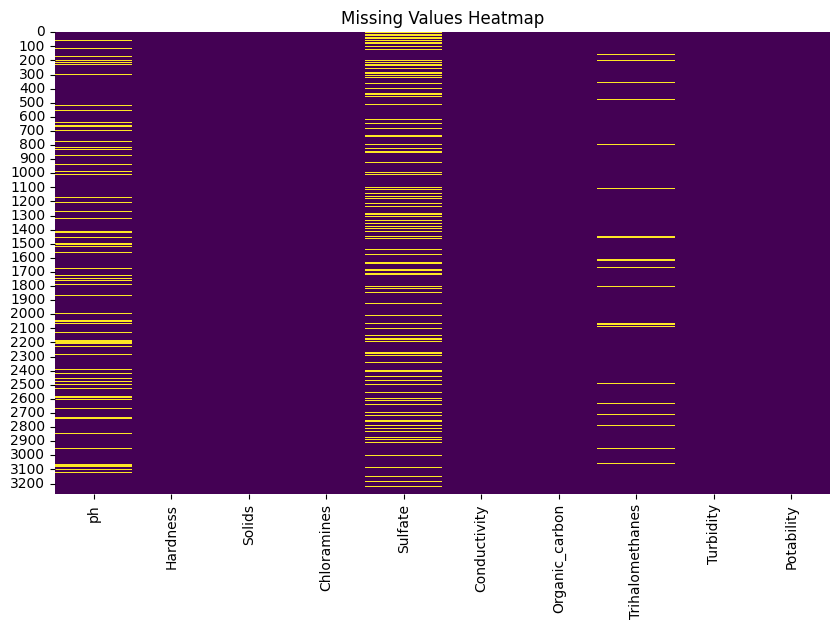

In [49]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")

plt.show()

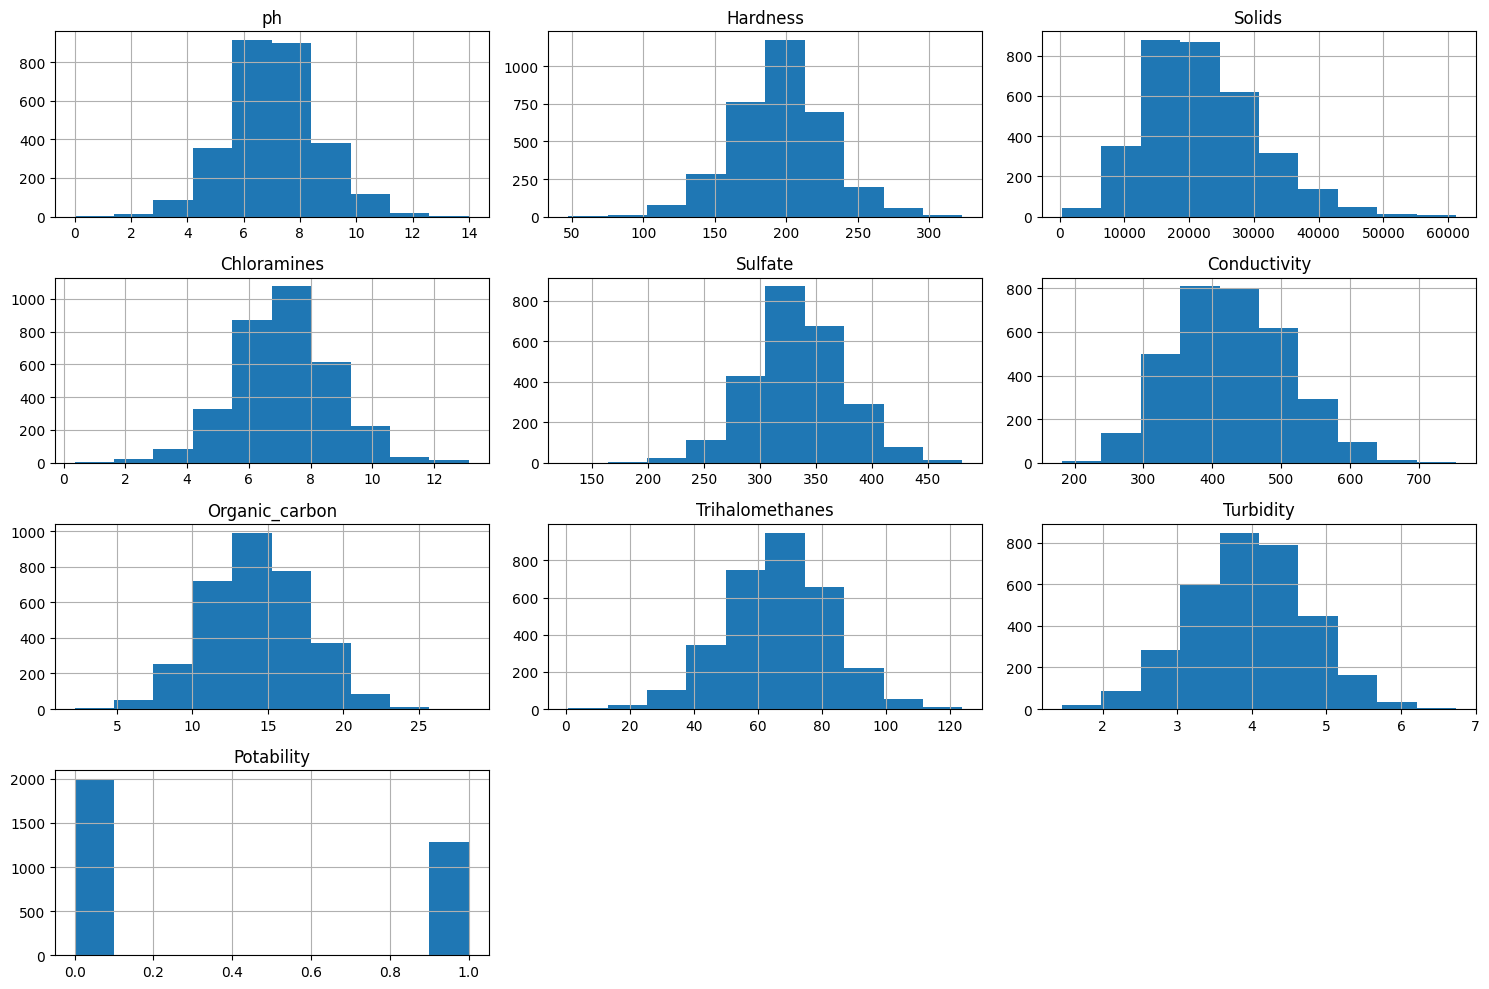

In [8]:
df.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

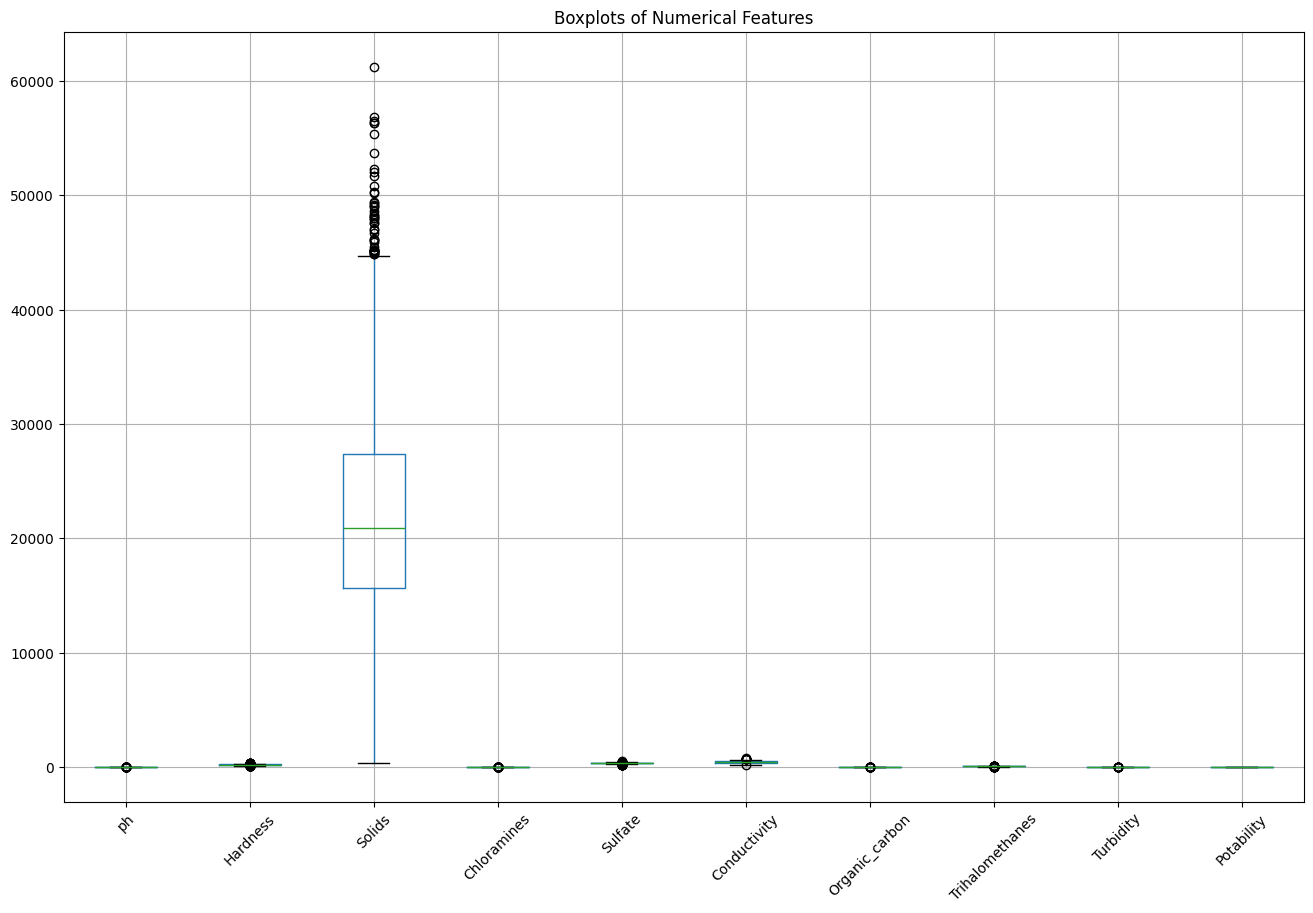

In [51]:
plt.figure(figsize=(16,10))

df.boxplot(rot=45)

plt.title("Boxplots of Numerical Features")

plt.show()

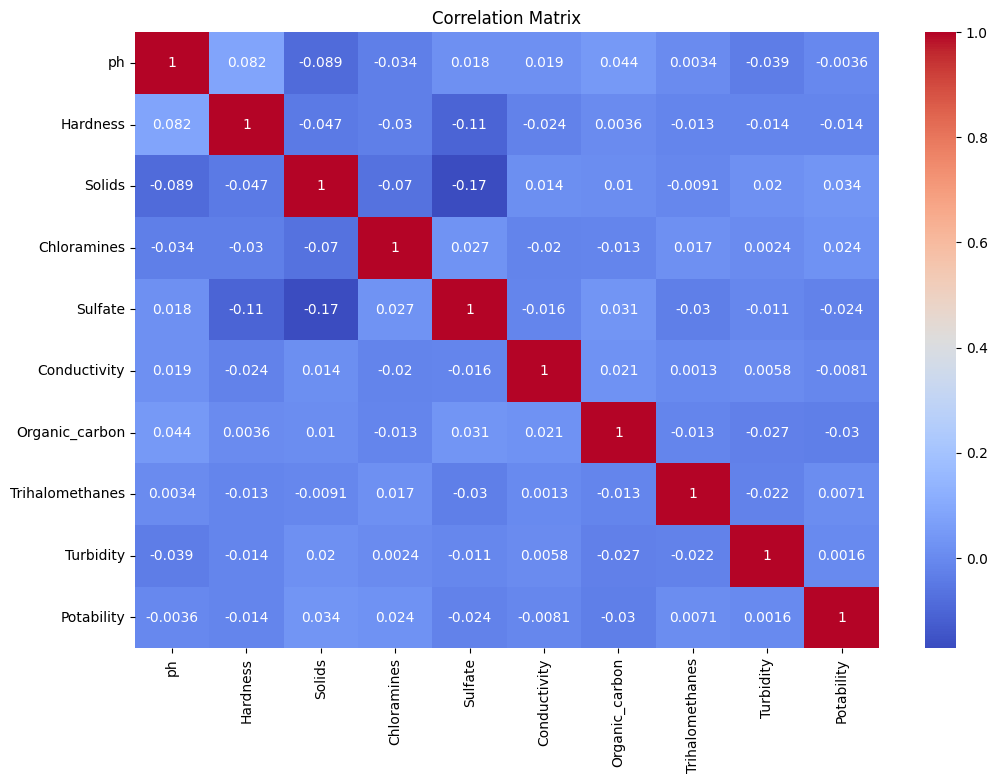

In [9]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

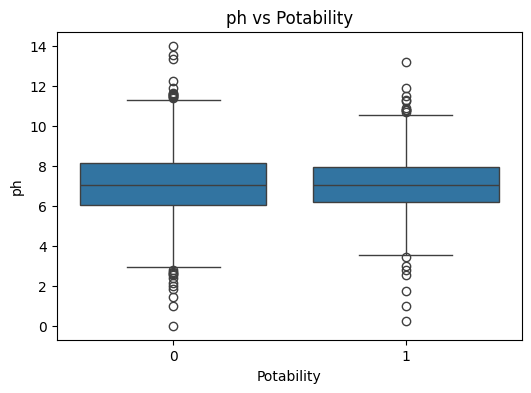

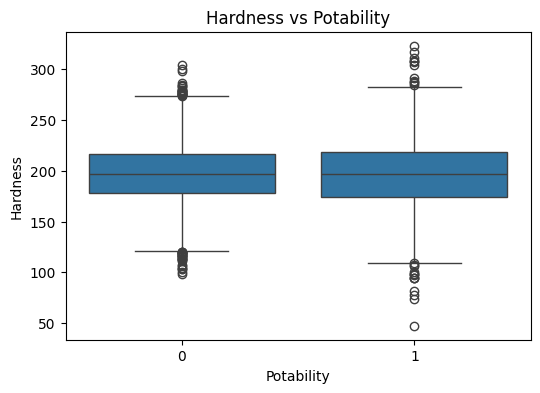

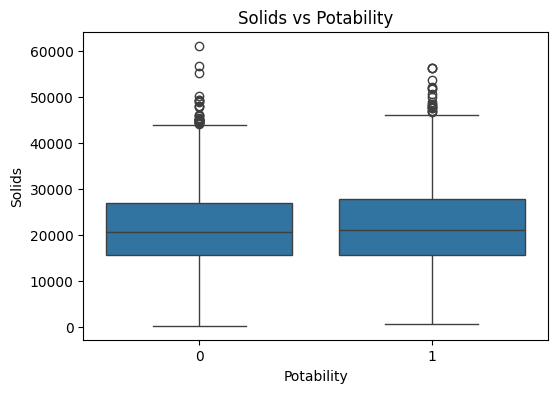

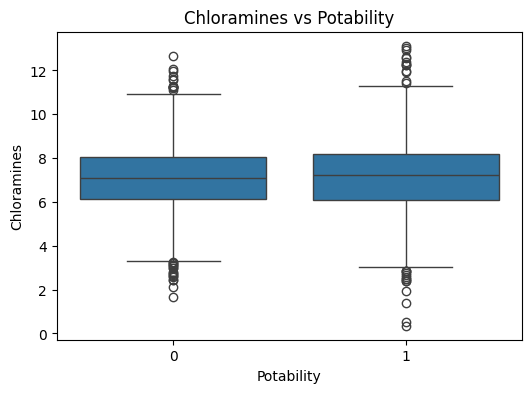

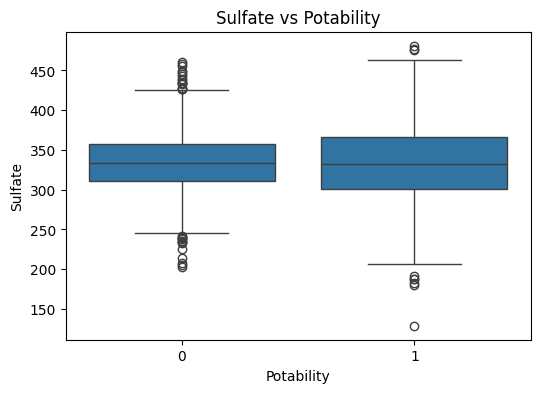

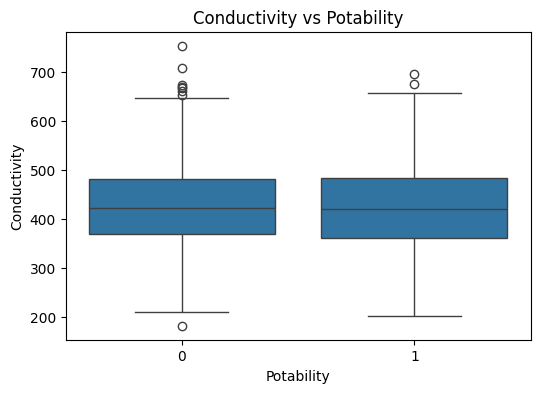

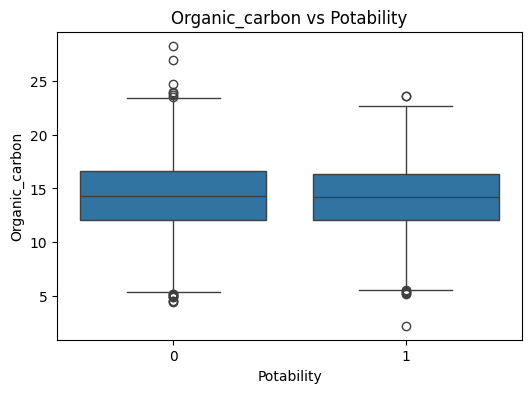

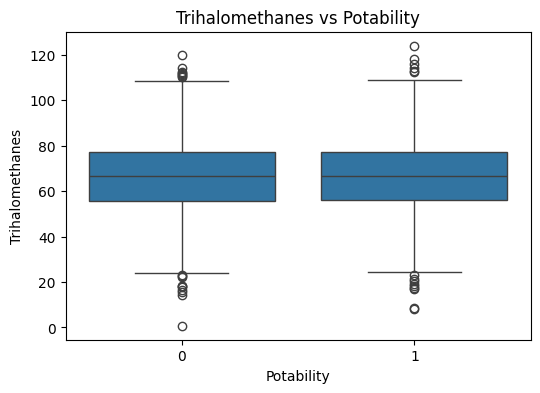

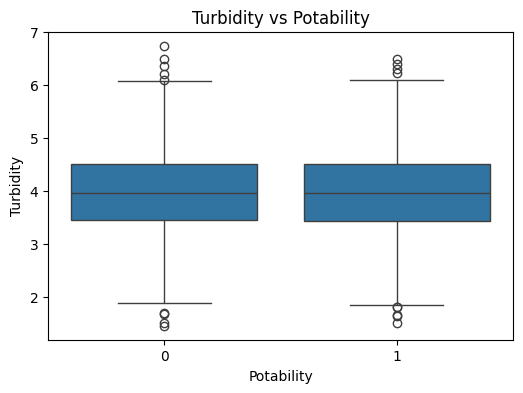

In [53]:
features = df.columns[:-1]

for feature in features:
    plt.figure(figsize=(6,4))

    sns.boxplot(
        data=df,
        x="Potability",
        y=feature
    )

    plt.title(f"{feature} vs Potability")

    plt.show()

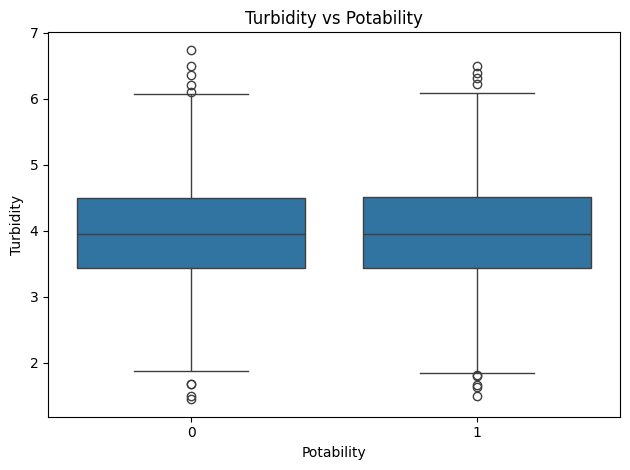

In [54]:
    sns.boxplot(
        data=df,
        x="Potability",
        y=feature
    )

    plt.title(f"{feature} vs Potability")
    plt.xlabel("Potability")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

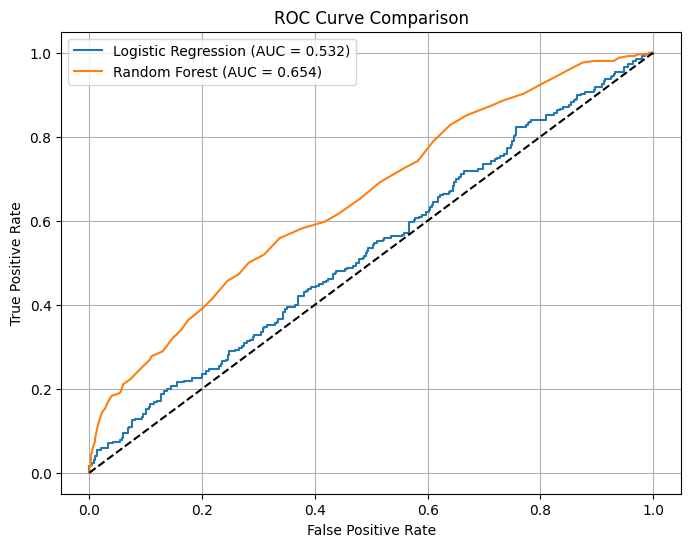

In [56]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()

plt.grid(True)

plt.show()

In [57]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.500000,0.400000,0.562500,0.467532,0.531875
1,Random Forest,0.650915,0.617391,0.277344,0.382749,0.653735


In [10]:
df.isnull().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


In [11]:
missing = (df.isnull().sum()/len(df))*100

print(missing.sort_values(ascending=False))

Sulfate            23.840049
ph                 14.987790
Trihalomethanes     4.945055
Hardness            0.000000
Chloramines         0.000000
Solids              0.000000
Conductivity        0.000000
Organic_carbon      0.000000
Turbidity           0.000000
Potability          0.000000
dtype: float64


In [12]:
from sklearn.model_selection import train_test_split

X = df.drop('Potability', axis=1)
y = df['Potability']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

print("Train:", X_train.shape[0], "| Val:", X_val.shape[0], "| Test:", X_test.shape[0])
print("NaN X_train:", X_train.isnull().sum().sum())
print("NaN X_val:", X_val.isnull().sum().sum())
print("NaN X_test:", X_test.isnull().sum().sum())

Train: 1965 | Val: 655 | Test: 656
NaN X_train: 0
NaN X_val: 0
NaN X_test: 0


In [13]:
print(X_train.describe())

                ph     Hardness        Solids  Chloramines      Sulfate  \
count  1965.000000  1965.000000   1965.000000  1965.000000  1965.000000   
mean      7.100929   196.199514  21801.295652     7.114577   333.725919   
std       1.444028    32.966981   8839.203886     1.594815    35.873052   
min       1.431782    47.432000    320.942611     0.352000   187.170714   
25%       6.334163   175.875828  15405.496481     6.113974   317.016465   
50%       7.051396   196.775056  20574.364258     7.108974   333.110932   
75%       7.860106   216.432576  27008.011874     8.136931   349.922852   
max      13.175402   323.124000  56867.859236    12.912187   481.030642   

       Conductivity  Organic_carbon  Trihalomethanes    Turbidity  
count   1965.000000     1965.000000      1965.000000  1965.000000  
mean     427.299633       14.339463        66.200745     3.968541  
std       80.167616        3.322908        15.957188     0.784846  
min      181.483754        2.200000         8.175876

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight='balanced'))
])
log_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [20]:
y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

In [21]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.5


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Precision: 0.4
Recall: 0.5625
F1 Score: 0.4675324675324675


In [23]:
from sklearn.metrics import roc_auc_score

print("ROC AUC:", roc_auc_score(y_test, y_prob))

ROC AUC: 0.531875


In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.62      0.46      0.53       400
           1       0.40      0.56      0.47       256

    accuracy                           0.50       656
   macro avg       0.51      0.51      0.50       656
weighted avg       0.54      0.50      0.50       656



In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[184 216]
 [112 144]]


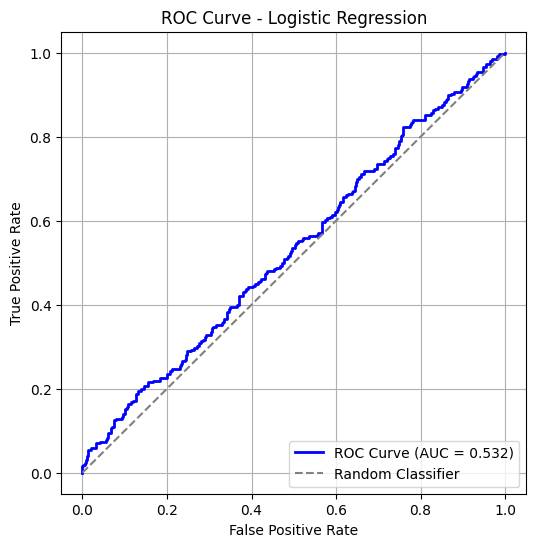

In [27]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calcularea curbei ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Afișarea graficului
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='blue', linewidth=2,
         label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})')

plt.plot([0,1], [0,1], linestyle='--', color='gray',
         label='Random Classifier')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

In [28]:
# Extragem coeficienții modelului Logistic Regression
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.named_steps["clf"].coef_[0]
})

# Sortăm coeficienții după valoare absolută
coefficients["Absolute"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values(by="Absolute", ascending=False)

# Afișăm tabelul
print(coefficients)

           Feature  Coefficient  Absolute
2           Solids     0.085626  0.085626
3      Chloramines     0.063947  0.063947
7  Trihalomethanes     0.063124  0.063124
5     Conductivity    -0.016583  0.016583
1         Hardness     0.015006  0.015006
4          Sulfate     0.007848  0.007848
0               ph     0.007477  0.007477
6   Organic_carbon    -0.006775  0.006775
8        Turbidity    -0.006001  0.006001


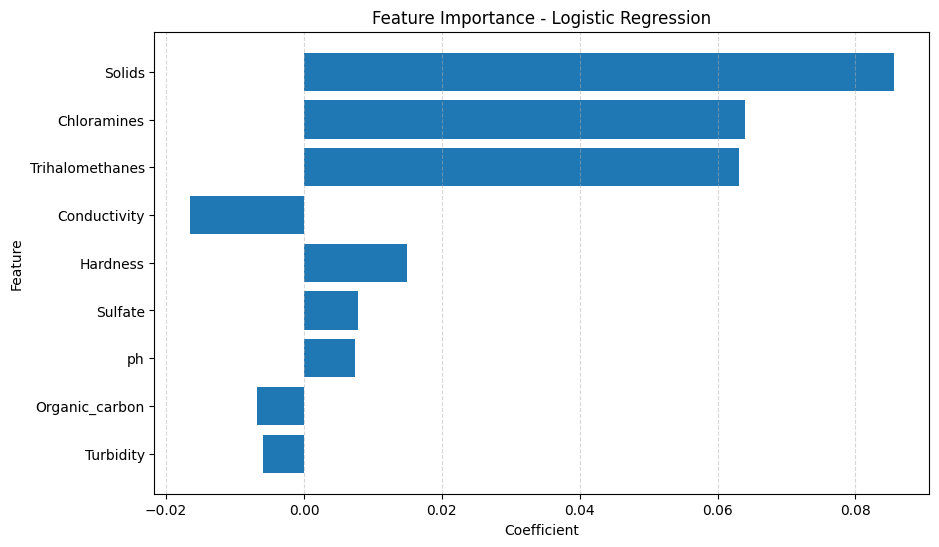

In [29]:
plt.figure(figsize=(10,6))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance - Logistic Regression")

plt.gca().invert_yaxis()  # Cea mai importantă variabilă apare sus
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [31]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

In [32]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [33]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:,1]

In [36]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, rf_pred))

Accuracy: 0.6509146341463414


In [37]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

Accuracy: 0.6509146341463414
Precision: 0.6173913043478261
Recall: 0.27734375
F1 Score: 0.38274932614555257


In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [39]:
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

Accuracy: 0.6509146341463414
Precision: 0.6173913043478261
Recall: 0.27734375
F1 Score: 0.38274932614555257


In [40]:
from sklearn.metrics import roc_auc_score

print("ROC AUC:", roc_auc_score(y_test, rf_prob))

ROC AUC: 0.6537353515625001


In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.66      0.89      0.76       400
           1       0.62      0.28      0.38       256

    accuracy                           0.65       656
   macro avg       0.64      0.58      0.57       656
weighted avg       0.64      0.65      0.61       656



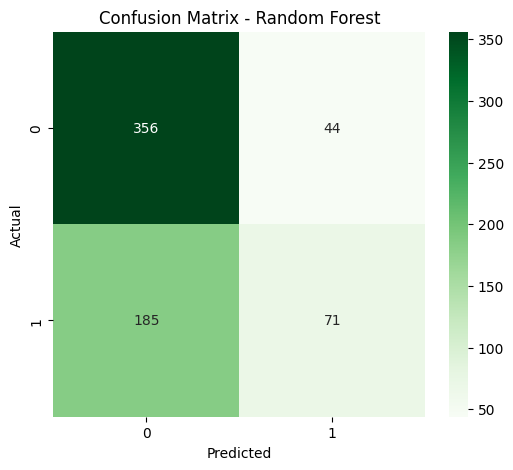

In [42]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

Precision: 0.6173913043478261
Recall: 0.27734375
F1 Score: 0.38274932614555257


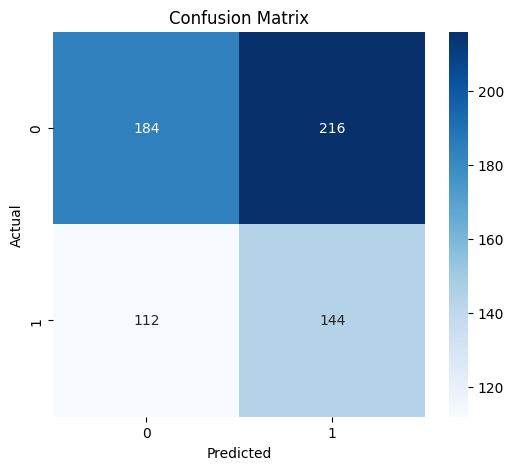

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [15]:
# Predicțiile modelului
y_pred = log_model.predict(X_test)

# Probabilitățile pentru clasa pozitivă
y_prob = log_model.predict_proba(X_test)[:, 1]

In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.5


In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Precision: 0.4
Recall: 0.5625
F1 Score: 0.4675324675324675


In [18]:
from sklearn.metrics import roc_auc_score

print("ROC AUC:", roc_auc_score(y_test, y_prob))

ROC AUC: 0.531875


In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.62      0.46      0.53       400
           1       0.40      0.56      0.47       256

    accuracy                           0.50       656
   macro avg       0.51      0.51      0.50       656
weighted avg       0.54      0.50      0.50       656



In [ ]:
from sklearn.metrics import classification_report

y_pred_log = log_model.predict(X_test)
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.62      0.46      0.53       400
           1       0.40      0.56      0.47       256

    accuracy                           0.50       656
   macro avg       0.51      0.51      0.50       656
weighted avg       0.54      0.50      0.50       656



In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.66      0.89      0.76       400
           1       0.62      0.28      0.38       256

    accuracy                           0.65       656
   macro avg       0.64      0.58      0.57       656
weighted avg       0.64      0.65      0.61       656



In [ ]:
import pandas as pd

importances = model.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(feat_imp)

ph                 0.128871
Sulfate            0.123317
Hardness           0.122425
Chloramines        0.111897
Solids             0.109419
Conductivity       0.102028
Turbidity          0.101725
Trihalomethanes    0.100550
Organic_carbon     0.099769
dtype: float64


In [ ]:
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score
import numpy as np

y_val_probs = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds_pr = precision_recall_curve(y_val, y_val_probs)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds_pr[best_idx]

print("Best threshold (ales pe validation):", best_threshold)
print("Precision (val):", precision[best_idx], "| Recall (val):", recall[best_idx])

y_test_probs = model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_probs >= best_threshold).astype(int)

print("\n--- Raport final pe TEST ---")
print(classification_report(y_test, y_test_pred))
print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs))

Best threshold (ales pe validation): 0.34
Precision (val): 0.4939467312348668 | Recall (val): 0.8

--- Raport final pe TEST ---
              precision    recall  f1-score   support

           0       0.72      0.44      0.54       400
           1       0.45      0.73      0.56       256

    accuracy                           0.55       656
   macro avg       0.58      0.58      0.55       656
weighted avg       0.61      0.55      0.55       656

ROC-AUC pe test: 0.6537353515625001


In [30]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Combinăm train + validation pentru cross-validation (test rămâne neatins)
import pandas as pd
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    X_train_full, y_train_full,
    cv=cv, scoring='roc_auc'
)

print("ROC-AUC pe fiecare fold:", cv_scores)
print("Media:", cv_scores.mean(), "| Deviația standard:", cv_scores.std())

ROC-AUC pe fiecare fold: [0.69372702 0.7154565  0.66488971 0.68900528 0.65813136]
Media: 0.6842419708560272 | Deviația standard: 0.02070399082592629


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_full, y_train_full)

print("Cei mai buni parametri:", grid_search.best_params_)
print("Cel mai bun scor ROC-AUC (cross-validation):", grid_search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Cei mai buni parametri: {'max_depth': 30, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}
Cel mai bun scor ROC-AUC (cross-validation): 0.6980213952935329


In [ ]:
best_model = grid_search.best_estimator_

# Threshold tuning pe validation, cu modelul optimizat
y_val_probs_best = best_model.predict_proba(X_val)[:, 1]
precision_b, recall_b, thresholds_pr_b = precision_recall_curve(y_val, y_val_probs_best)
f1_scores_b = 2 * (precision_b * recall_b) / (precision_b + recall_b + 1e-8)
best_idx_b = np.argmax(f1_scores_b)
best_threshold_b = thresholds_pr_b[best_idx_b]

print("Best threshold (model optimizat):", best_threshold_b)

# Evaluare finală pe test
y_test_probs_best = best_model.predict_proba(X_test)[:, 1]
y_test_pred_best = (y_test_probs_best >= best_threshold_b).astype(int)

print("\n--- Raport final pe TEST (model optimizat) ---")
print(classification_report(y_test, y_test_pred_best))
print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs_best))

Best threshold (model optimizat): 0.4882386713748618

--- Raport final pe TEST (model optimizat) ---
              precision    recall  f1-score   support

           0       0.69      0.83      0.75       400
           1       0.61      0.43      0.50       256

    accuracy                           0.67       656
   macro avg       0.65      0.63      0.63       656
weighted avg       0.66      0.67      0.66       656

ROC-AUC pe test: 0.667392578125


In [ ]:
from sklearn.metrics import fbeta_score, precision_recall_curve, classification_report, roc_auc_score
import numpy as np

# beta > 1 => recall contează mai mult decât precision
# beta=2 e un standard comun pentru "recall e de 2x mai important"
beta = 2

y_val_probs_best = best_model.predict_proba(X_val)[:, 1]
precision_r, recall_r, thresholds_r = precision_recall_curve(y_val, y_val_probs_best)

# F-beta pentru fiecare threshold din precision_recall_curve
fbeta_scores = (1 + beta**2) * (precision_r * recall_r) / (beta**2 * precision_r + recall_r + 1e-8)
best_idx_r = np.argmax(fbeta_scores)
best_threshold_recall = thresholds_r[best_idx_r]

print(f"Best threshold (optimizat pentru recall, beta={beta}):", best_threshold_recall)
print("Precision (val):", precision_r[best_idx_r], "| Recall (val):", recall_r[best_idx_r])

# Evaluare finală pe test
y_test_probs_best = best_model.predict_proba(X_test)[:, 1]
y_test_pred_recall = (y_test_probs_best >= best_threshold_recall).astype(int)

print("\n--- Raport final pe TEST (threshold optimizat pentru recall) ---")
print(classification_report(y_test, y_test_pred_recall))
print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs_best))

Best threshold (optimizat pentru recall, beta=2): 0.4882386713748618
Precision (val): 0.9807692307692307 | Recall (val): 1.0

--- Raport final pe TEST (threshold optimizat pentru recall) ---
              precision    recall  f1-score   support

           0       0.69      0.83      0.75       400
           1       0.61      0.43      0.50       256

    accuracy                           0.67       656
   macro avg       0.65      0.63      0.63       656
weighted avg       0.66      0.67      0.66       656

ROC-AUC pe test: 0.667392578125


In [ ]:
print(f"{'Threshold':<12}{'Precision':<12}{'Recall':<12}")
print("-" * 36)
for i in range(len(thresholds_r)):
    if recall_r[i] >= 0.80:  # schimbă pragul minim de recall aici
        print(f"{thresholds_r[i]:<12.3f}{precision_r[i]:<12.3f}{recall_r[i]:<12.3f}")

Threshold   Precision   Recall      
------------------------------------
0.043       0.389       1.000       
0.053       0.390       1.000       
0.062       0.391       1.000       
0.064       0.391       1.000       
0.068       0.392       1.000       
0.070       0.392       1.000       
0.086       0.393       1.000       
0.091       0.394       1.000       
0.097       0.394       1.000       
0.100       0.395       1.000       
0.101       0.395       1.000       
0.103       0.396       1.000       
0.106       0.397       1.000       
0.106       0.397       1.000       
0.106       0.398       1.000       
0.106       0.398       1.000       
0.107       0.399       1.000       
0.111       0.400       1.000       
0.114       0.400       1.000       
0.114       0.401       1.000       
0.117       0.402       1.000       
0.118       0.402       1.000       
0.119       0.403       1.000       
0.121       0.403       1.000       
0.122       0.404       1.000       
0

In [ ]:
from sklearn.metrics import fbeta_score, precision_recall_curve, classification_report, roc_auc_score
import numpy as np

beta = 2

y_val_probs_best = best_model.predict_proba(X_val)[:, 1]
precision_r, recall_r, thresholds_r = precision_recall_curve(y_val, y_val_probs_best)

fbeta_scores = (1 + beta**2) * (precision_r * recall_r) / (beta**2 * precision_r + recall_r + 1e-8)
best_idx_r = np.argmax(fbeta_scores)
best_threshold_recall = thresholds_r[best_idx_r]

print(f"Best threshold (optimizat pentru recall, beta={beta}):", best_threshold_recall)
print("Precision (val):", precision_r[best_idx_r], "| Recall (val):", recall_r[best_idx_r])

y_test_probs_best = best_model.predict_proba(X_test)[:, 1]
y_test_pred_recall = (y_test_probs_best >= best_threshold_recall).astype(int)

print("\n--- Raport final pe TEST (threshold optimizat pentru recall) ---")
print(classification_report(y_test, y_test_pred_recall))
print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs_best))

Best threshold (optimizat pentru recall, beta=2): 0.4882386713748618
Precision (val): 0.9807692307692307 | Recall (val): 1.0

--- Raport final pe TEST (threshold optimizat pentru recall) ---
              precision    recall  f1-score   support

           0       0.69      0.83      0.75       400
           1       0.61      0.43      0.50       256

    accuracy                           0.67       656
   macro avg       0.65      0.63      0.63       656
weighted avg       0.66      0.67      0.66       656

ROC-AUC pe test: 0.667392578125


In [ ]:
import numpy as np

target_recall = 0.85  # poți ajusta acest prag

y_val_probs_best = best_model.predict_proba(X_val)[:, 1]
precision_r, recall_r, thresholds_r = precision_recall_curve(y_val, y_val_probs_best)

# Găsim toate punctele care ating recall-ul minim dorit
valid_mask = recall_r[:-1] >= target_recall  # thresholds_r are cu 1 element mai puțin

if valid_mask.sum() == 0:
    print(f"Niciun threshold nu atinge recall {target_recall} pe validation!")
else:
    # Dintre cele valide, alegem pe cel cu precision maxim
    valid_indices = np.where(valid_mask)[0]
    best_idx_constrained = valid_indices[np.argmax(precision_r[valid_indices])]
    best_threshold_constrained = thresholds_r[best_idx_constrained]

    print(f"Threshold ales (recall >= {target_recall} pe validation):", best_threshold_constrained)
    print("Precision (val):", precision_r[best_idx_constrained], "| Recall (val):", recall_r[best_idx_constrained])

    # Evaluare finală pe test
    y_test_probs_best = best_model.predict_proba(X_test)[:, 1]
    y_test_pred_constrained = (y_test_probs_best >= best_threshold_constrained).astype(int)

    print("\n--- Raport final pe TEST ---")
    print(classification_report(y_test, y_test_pred_constrained))
    print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs_best))

Threshold ales (recall >= 0.85 pe validation): 0.5790542352960218
Precision (val): 1.0 | Recall (val): 0.9411764705882353

--- Raport final pe TEST ---
              precision    recall  f1-score   support

           0       0.66      0.95      0.78       400
           1       0.75      0.22      0.34       256

    accuracy                           0.67       656
   macro avg       0.70      0.59      0.56       656
weighted avg       0.69      0.67      0.61       656

ROC-AUC pe test: 0.667392578125


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score
import numpy as np

# Generăm probabilități out-of-fold pe TOT setul train_full (mai stabil decât un singur X_val)
oof_probs = cross_val_predict(
    best_model, X_train_full, y_train_full,
    cv=5, method='predict_proba', n_jobs=-1
)[:, 1]

precision_oof, recall_oof, thresholds_oof = precision_recall_curve(y_train_full, oof_probs)

target_recall = 0.85
valid_mask = recall_oof[:-1] >= target_recall

if valid_mask.sum() == 0:
    print(f"Niciun threshold nu atinge recall {target_recall}!")
else:
    valid_indices = np.where(valid_mask)[0]
    best_idx_oof = valid_indices[np.argmax(precision_oof[valid_indices])]
    best_threshold_oof = thresholds_oof[best_idx_oof]

    print(f"Threshold ales (cross-validation, recall >= {target_recall}):", best_threshold_oof)
    print("Precision (CV):", precision_oof[best_idx_oof], "| Recall (CV):", recall_oof[best_idx_oof])

# Reantrenăm modelul pe TOT train_full (mai multe date = model mai bun) și evaluăm o singură dată pe test
best_model.fit(X_train_full, y_train_full)

y_test_probs_final = best_model.predict_proba(X_test)[:, 1]
y_test_pred_final = (y_test_probs_final >= best_threshold_oof).astype(int)

print("\n--- Raport final pe TEST (threshold robust din CV) ---")
print(classification_report(y_test, y_test_pred_final))
print("ROC-AUC pe test:", roc_auc_score(y_test, y_test_probs_final))

Threshold ales (cross-validation, recall >= 0.85): 0.34277224718528415
Precision (CV): 0.4523316062176166 | Recall (CV): 0.8542074363992173

--- Raport final pe TEST (threshold robust din CV) ---
              precision    recall  f1-score   support

           0       0.76      0.35      0.48       400
           1       0.45      0.83      0.58       256

    accuracy                           0.54       656
   macro avg       0.61      0.59      0.53       656
weighted avg       0.64      0.54      0.52       656

ROC-AUC pe test: 0.667392578125


In [43]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.500000,0.400000,0.562500,0.467532,0.531875
1,Random Forest,0.650915,0.617391,0.277344,0.382749,0.653735
